## Semiconductor Lab B7 - Task 2

Measure the P-I characteristics for pulsed excitation in the range from 0...200 mA at 5
temperatures between 15 and 50°C and determine T0

In [1]:
%matplotlib inline

import math
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from scipy.optimize import curve_fit

from b7.python.config import DATA_DIR, DOUBLE_COLUMN, PLOTS_DIR
from b7.python.helper import enrich_data_frame, pt_temperature

In [2]:
from pathlib import Path

data_dir: Path = DATA_DIR / "task_1_2"
export_dir: Path = PLOTS_DIR

### Import Data

In [3]:
files: list[str] = [
    "Messdaten B7 - Raumtemperatur (108.48 Ohm).csv",
    "Messdaten B7 - 15°C (105.7 Ohm).csv",
    "Messdaten B7 - 30°C (111.6 Ohm).csv",
    "Messdaten B7 - 40°C (115.6 Ohm).csv",
    "Messdaten B7 - 50°C (119.23 Ohm).csv",
]
resistances: list[float] = [108.48, 105.7, 111.6, 115.6, 119.23]

In [4]:
dfs: list[pd.DataFrame] = [pd.read_csv(data_dir / file) for file in files]

## Enrich Data

### DataFrame Enrichment

In [5]:
dfs_enriched: list[pd.DataFrame] = [enrich_data_frame(df) for df in dfs]
temperatures: list[float] = [273.15 + pt_temperature(r) for r in resistances]
temperatures_deg = [tmp - 273.15 for tmp in temperatures]

In [6]:
def lasing_branch(I: npt.NDArray[np.float64], m: float, I_th: float) -> npt.NDArray[np.float64]:
    """Optical output power above threshold: linear in I, reaching zero at I_th."""
    return m * (I - I_th)

In [7]:
I_ths: list[float] = []

for df in dfs_enriched:
    mask: pd.Series[bool] = df["P_opt_mW"] > 0.1
    (m, I_th), cov = curve_fit(lasing_branch, df[mask]["I"], df[mask]["P_opt"])
    I_ths.append(float(I_th))


In [8]:
temperature_data = [
    {"temperature": T, "I_th": I_th, "temperatured_deg": T_deg}
    for (T, T_deg, I_th) in zip(temperatures, temperatures_deg, I_ths)
]
pprint(temperature_data)

[{'I_th': 0.012807915670468009,
  'temperature': 294.91742612778745,
  'temperatured_deg': 21.767426127787473},
 {'I_th': 0.012124977377292954,
  'temperature': 287.76591187168515,
  'temperatured_deg': 14.61591187168517},
 {'I_th': 0.01357895263858682,
  'temperature': 302.9617461480304,
  'temperatured_deg': 29.81174614803041},
 {'I_th': 0.01494385879952258,
  'temperature': 313.3032879960742,
  'temperatured_deg': 40.1532879960742},
 {'I_th': 0.016341921000104915,
  'temperature': 322.71599934448807,
  'temperatured_deg': 49.56599934448809}]


In [9]:
T_1: float = temperatures[0]
I_1: float = I_ths[0]


def linear(T: npt.NDArray[np.float64], T_0: float) -> npt.NDArray[np.float64]:
    return math.log(I_1) + (T - T_1) / T_0


In [10]:
T_0, cov = curve_fit(linear, temperatures, np.log(I_ths))
pprint({"T_0": {"value": T_0[0], "delta": np.sqrt(cov[0][0])}})

{'T_0': {'delta': np.float64(2.70958093705202),
         'value': np.float64(117.14130279701213)}}


## Plot Data

In [11]:
I_ths_mA = [I_th * 1e3 for I_th in I_ths]
V_ths = [0 for _ in I_ths]

T_fit = np.linspace(280, 330, 100)
I_ths_fit = np.exp(linear(T_fit, T_0))
I_ths_fit_mA = I_ths_fit * 1e3

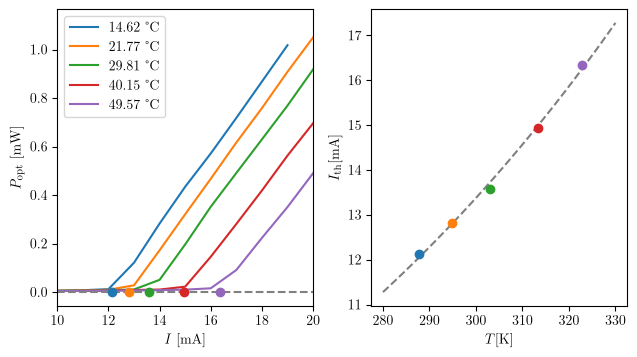

In [12]:
with plt.rc_context(DOUBLE_COLUMN):
    fig: Figure = plt.figure(layout="constrained")
    ax1: Axes = fig.add_subplot(1, 2, 1)
    ax2: Axes = fig.add_subplot(1, 2, 2)

    order = np.argsort(temperatures_deg)  # Indizes, aufsteigend nach Temperatur

    for i in order:
        df = dfs_enriched[i]
        temperature = f"{temperatures_deg[i]:.2f} °C"
        ax1.plot(df["I_mA"], df["P_opt_mW"], label=temperature)
        ax1.scatter(I_ths_mA[i], 0, zorder=100)
    ax1.set_xlabel(r"$I$ [\unit{\milli\ampere}]")
    ax1.set_ylabel(r"$P_\mathrm{opt}$ [\unit{\milli\watt}]")
    ax1.set_xlim(10, 20)
    ax1.hlines(y=0, xmin=10, xmax=100, color="grey", linestyle="--")
    ax1.legend()

    for i in order:
        ax2.scatter(temperatures[i], I_ths_mA[i])
    ax2.set_xlabel(r"$T [\unit{\kelvin}]$")
    ax2.set_ylabel(r"$I_{\mathrm{th}} [\unit{\milli\ampere}]$")
    ax2.plot(T_fit, I_ths_fit_mA, color="grey", linestyle="--", zorder=-1)

    plt.savefig(export_dir / "task2.pdf")
    plt.show()

Caption: Power-current characteristics of the laser diode for different temperatures (left) and Threshold current as a function of temoerature (right)

- Power-current characteristic curves were recorded for different temperatures, ranging from 14 to 50°C
- temperature shifts the threshold current
- this shift can be fitted empirically by eq (...)
- this results in a characteristic temperature of 117+-3 K